## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [23]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Geethan Sundaram

**Date:** 10/19/2026

-- Q1 --
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


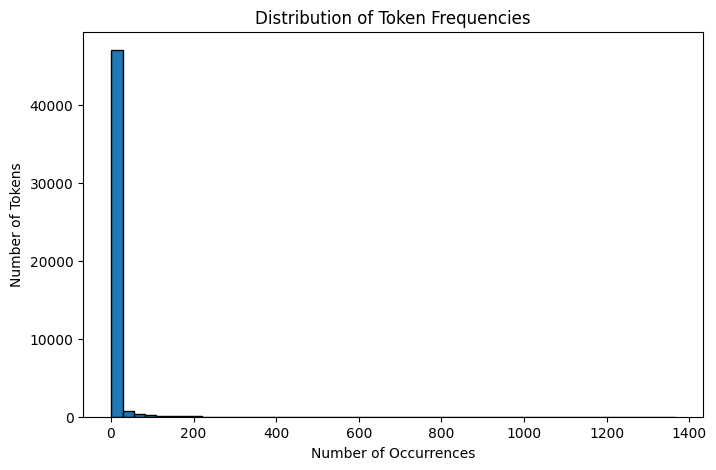

The distribution is extremely right skewed. Most tokens tend to only appear a
few times, while a very trivial number of tokens appear far more often. A large
concentration of tokens are located in the left side of the histogram which a
very long tail towards the right of the histogram. This shows us that certain
words are used far more often than others, even after common words are removed.
A whopping 29,404 unique tokens appeared only one time, while the most frequent
token, 'new', appears 1,365 times.


In [24]:
print("-- Q1 --")

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
import textwrap

# load the token data
with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_freq[:10])

counts = list(token_count.values())

# plot the histogram of token frequencies
plt.figure(figsize=(8, 5))
plt.hist(counts, bins=50, edgecolor='black')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')
plt.show()

text = "The distribution is extremely right skewed. Most tokens tend to only appear a few times, while a very trivial number of tokens appear far more often. A large concentration of tokens are located in the left side of the histogram which a very long tail towards the right of the histogram. This shows us that certain words are used far more often than others, even after common words are removed. A whopping 29,404 unique tokens appeared only one time, while the most frequent token, 'new', appears 1,365 times."

print("\n".join(textwrap.wrap(text, width=80)))  

In [25]:
print("-- Q2 --")

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy.sparse import csr_matrix

# Load the data
file_path = Path('data/Phishing_clean.parquet')
if not file_path.exists():
    file_path = Path('Phishing_clean.parquet')

df = pd.read_parquet(file_path)

# split the data into features and target
X = df.drop(columns=['Email Type'])
y = df['Email Type']

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train rows:', len(X_train))
print('Test rows:', len(X_test))
print('Number of features:', X.shape[1])

# Train a linear regression model
model = LinearRegression()
model.fit(csr_matrix(X_train), y_train)

train_r2 = model.score(csr_matrix(X_train), y_train)
test_r2 = model.score(csr_matrix(X_test), y_test)

print('Training R²:', round(train_r2, 4))
print('Test R²:', round(test_r2, 4))

coefficients = pd.Series(model.coef_, index=X.columns)
top_words = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
)
print('Top 10 tokens by absolute coefficient:')
print(top_words.head(10).round(4))

text = "The training R^2 was 0.7713 and the test R^2 was 0.6424. The model does fit the training data more effectively, so there may be overfitting present. The largest coefficients seemed to be for 'background-image:', 'localized', 'thermal', 'aging', and 'erectile'. The positive coefficients bring the prediction towards phishing (1), while the negative coefficients push it towards normal (0) instead. I did also notice how certain features were pieces of HTML or some kind of formatting rather than genuine words."

print("\n".join(textwrap.wrap(text, width=80)))


-- Q2 --
Train rows: 14907
Test rows: 3727
Number of features: 2711
Training R²: 0.7713
Test R²: 0.6424
Top 10 tokens by absolute coefficient:
background-image:   -1.0160
localized            0.8395
thermal              0.6996
#331f30;             0.6159
#000000;             0.6158
form.                0.5937
aging                0.5867
erectile             0.5385
girlfriend           0.5276
xanaax               0.5164
dtype: float64
The training R^2 was 0.7713 and the test R^2 was 0.6424. The model does fit the
training data more effectively, so there may be overfitting present. The largest
coefficients seemed to be for 'background-image:', 'localized', 'thermal',
'aging', and 'erectile'. The positive coefficients bring the prediction towards
phishing (1), while the negative coefficients push it towards normal (0)
instead. I did also notice how certain features were pieces of HTML or some kind
of formatting rather than genuine words.


-- Q3 --


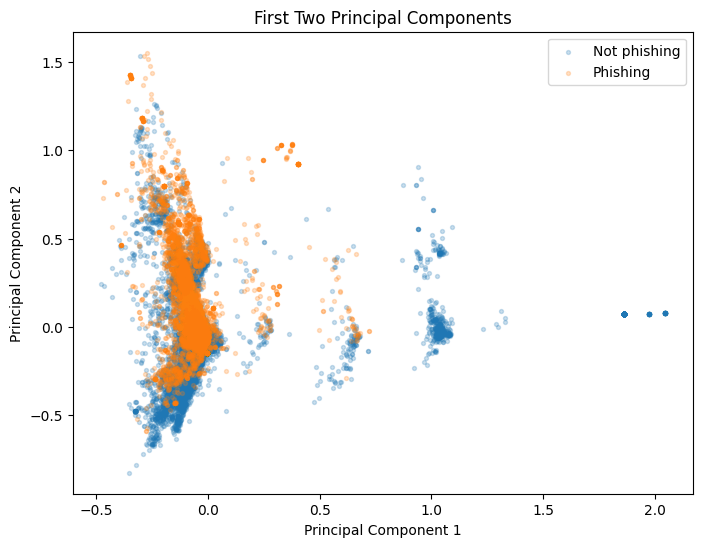

Explained variance ratios: [0.0111 0.0086]
There exists massive overlap between the phishing and non-phishing emails,
particularly around the main cluster towards the left. Interestingly, there
existed groups farther to the right that were mostly filled with non-phishing
emails. It also seemed that several phishing emails stayed concentrated a little
higher on the second component. Overall, the first two components show a few
patterns, but there isn't a clear separation of the two types of emails.


In [26]:
print("-- Q3 --")

from sklearn.decomposition import PCA

# perform PCA to reduce the dimensionality of the data
pca2 = PCA(n_components=2, svd_solver='randomized', random_state=42)
X_pca2 = pca2.fit_transform(X.to_numpy(dtype=np.float32))

# plot the first two principal components
plt.figure(figsize=(8, 6))
plt.scatter(X_pca2[y == 0, 0], X_pca2[y == 0, 1],
            label='Not phishing', alpha=0.23, s=8)
plt.scatter(X_pca2[y == 1, 0], X_pca2[y == 1, 1],
            label='Phishing', alpha=0.23, s=8)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('First Two Principal Components')
plt.legend()
plt.show()

print('Explained variance ratios:', pca2.explained_variance_ratio_.round(4))

text = "There exists massive overlap between the phishing and non-phishing emails, particularly around the main cluster towards the left. Interestingly, there existed groups farther to the right that were mostly filled with non-phishing emails. It also seemed that several phishing emails stayed concentrated a little higher on the second component. Overall, the first two components show a few patterns, but there isn't a clear separation of the two types of emails."

print("\n".join(textwrap.wrap(text, width=80)))

In [27]:
print("-- Q4 --")

# perform PCA to reduce the dimensionality of the data
pca_large = PCA(n_components=2610, svd_solver='covariance_eigh')
X_train_pca = pca_large.fit_transform(X_train.to_numpy(dtype=np.float32))
X_test_pca = pca_large.transform(X_test.to_numpy(dtype=np.float32))

# Train a linear regression model on the PCA-transformed data
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

pca_train_r2 = pca_model.score(X_train_pca, y_train)
pca_test_r2 = pca_model.score(X_test_pca, y_test)

print('PCA training R²:', round(pca_train_r2, 4))
print('PCA test R²:', round(pca_test_r2, 4))
print('Original training R²:', round(train_r2, 4))
print('Original test R²:', round(test_r2, 4))

text = "With the first 2610 principal components, the training R^2 for the regression was 0.7707 and the test R^2 was 0.6450. This training score is a bit less compared  to the original regression by 0.0006, but the test score did slightly improve by 0.0026. This indicates that removing some of the less important variation did help with overfitting, but it is a very small difference. Since we did keep 2610 out of the 2711 components, the two models overall performed similarly."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q4 --
PCA training R²: 0.7707
PCA test R²: 0.645
Original training R²: 0.7713
Original test R²: 0.6424
With the first 2610 principal components, the training R^2 for the regression
was 0.7707 and the test R^2 was 0.6450. This training score is a bit less
compared  to the original regression by 0.0006, but the test score did slightly
improve by 0.0026. This indicates that removing some of the less important
variation did help with overfitting, but it is a very small difference. Since we
did keep 2610 out of the 2711 components, the two models overall performed
similarly.


In [28]:
print("-- Q5 --")

text = "A major advantage of using principal components is that it lets us use fewer features without sacrificing too much information from the original data. In this case especially, there appear to be thousands of different words, and some of them are probably related to each other or appear together in the same emails. PCA combines original features into new components that have no correlation. This makes it easier to work with a massive dataset and does indeed help reduce overfitting. At times, even if minor, regression can also be made more speedy if substantially fewer components are kept. There is a downside, however. The components tend to be harder to interpret because they don't represent individual words anymore. There's also no accuracy improvement, since components with the most variation aren't really the most useful when it comes to predicting phishing."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q5 --
A major advantage of using principal components is that it lets us use fewer
features without sacrificing too much information from the original data. In
this case especially, there appear to be thousands of different words, and some
of them are probably related to each other or appear together in the same
emails. PCA combines original features into new components that have no
correlation. This makes it easier to work with a massive dataset and does indeed
help reduce overfitting. At times, even if minor, regression can also be made
more speedy if substantially fewer components are kept. There is a downside,
however. The components tend to be harder to interpret because they don't
represent individual words anymore. There's also no accuracy improvement, since
components with the most variation aren't really the most useful when it comes
to predicting phishing.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** e62653a05f9bc03633880c5565e541d9cf870836
- **AI tool and model used:** GPT-6 Astra

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


### 1. Q1: Keep the interpretation, but improve histogram readability

The original histogram correctly plots the distribution of occurrence counts across unique tokens. The interpretation of an extremely right-skewed distribution is correct.

The data contains:

- **48,691 unique tokens**
- **29,404 tokens occurring exactly once**
- **1,365 occurrences of `"new"`, the most frequent token**

However, 50 equally spaced bins compress most tokens into the first bar. Keep the original histogram and optionally add a second histogram with logarithmically spaced bins:

```python
counts = np.array(list(token_count.values()))
bins = np.geomspace(1, counts.max() + 1, 40)

plt.figure(figsize=(8, 5))
plt.hist(counts, bins=bins, edgecolor="black")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Occurrences per unique token (log scale)")
plt.ylabel("Number of unique tokens (log scale)")
plt.title("Distribution of Token Frequencies")
plt.show()
```

Calculate the singleton count directly rather than hard-coding it:

```python
singleton_count = np.count_nonzero(counts == 1)
print(f"Tokens occurring exactly once: {singleton_count:,}")
```

### 2. Q2: Add data checks and acknowledge inconsistencies in the supplied dataset

The dataset contains **18,634 emails and 2,711 binary features**, with no missing feature values.

However, it also contains:

- **55 all-zero feature columns**
- **170 columns occurring in fewer than 15 emails**, including the 55 all-zero columns
- **67 duplicate feature columns**, counting repeated copies beyond the first

Therefore, the assignment’s statement that each feature occurs in at least 15 emails does not describe every column in the supplied file. This is a property of the provided data, not an error in the Phase 1 code.

Add checks such as:

```python
assert X.index.equals(y.index)
assert not X.isna().any().any()
assert not y.isna().any()
assert X.isin([0, 1]).all().all()
assert set(y.unique()) == {0, 1}

print("All-zero columns:", X.sum().eq(0).sum())
print("Columns occurring in fewer than 15 emails:", X.sum().lt(15).sum())
```

Retaining the supplied columns is reasonable for the assignment, especially because Q4 specifies an exact number of principal components.

If constant columns are removed, identify them using the training data and apply the same selection to the test data.

### 3. Q2: Correct the coefficient discussion and qualify its interpretation

The coefficient sorting is correct, but the written explanation skips several coefficients that precede `"aging"` and `"erectile"`.

The actual top five tokens by absolute coefficient are:

| Token | Coefficient |
|---|---:|
| `background-image:` | −1.0160 |
| `localized` | +0.8395 |
| `thermal` | +0.6996 |
| `#331f30;` | +0.6159 |
| `#000000;` | +0.6158 |

For binary predictors, a coefficient describes the change in the fitted prediction when that feature changes from 0 to 1, **holding the other features fixed**.

Large absolute coefficients do not necessarily establish reliable overall predictive importance. Correlated or duplicate columns can make individual coefficients unstable or nonunique.

The positive/negative interpretation is broadly correct:

- Positive coefficients increase the fitted phishing score.
- Negative coefficients decrease the fitted phishing score.

However, linear regression can produce predictions below 0 or above 1. Its predictions are not guaranteed probabilities, and **R² is not classification accuracy**.

Keep linear regression and R² because those are explicitly requested by the assignment.

### 4. Q2 and Q4: Reuse sparse matrices and preserve the same train/test split

Only approximately **0.315%** of feature entries are nonzero, so sparse matrices are appropriate for Q2.

Avoid repeatedly converting the same data:

```python
X_train_sparse = csr_matrix(X_train)
X_test_sparse = csr_matrix(X_test)

model = LinearRegression()
model.fit(X_train_sparse, y_train)

train_r2 = model.score(X_train_sparse, y_train)
test_r2 = model.score(X_test_sparse, y_test)
```

The stratified 80/20 split and fixed random seed are sensible.

Keep the same split for the original regression and PCA regression so their scores remain comparable.

### 5. Q3: Explain how little variance the first two components capture

The plot and the explanation of substantial overlap are consistent.

The saved explained-variance ratios are:

| Component | Explained variance |
|---|---:|
| PC1 | Approximately 1.11% |
| PC2 | Approximately 0.86% |
| Combined | Approximately 1.97% |

Include these percentages in the axis labels:

```python
plt.xlabel(
    f"Principal Component 1 "
    f"({pca2.explained_variance_ratio_[0]:.2%} variance)"
)
plt.ylabel(
    f"Principal Component 2 "
    f"({pca2.explained_variance_ratio_[1]:.2%} variance)"
)
```

The overlap shows that these two components do not clearly separate phishing and non-phishing emails. It does **not** establish that the full feature set cannot distinguish the classes.

Fitting PCA on all of `X` is acceptable for the descriptive plot requested in Q3. It does not contaminate Q4 because Q4 correctly fits a separate PCA using only `X_train`.

Preserve that separation.

### 6. Q4: Treat higher precision as optional and report retained variance

The `float32` implementation reproduces the saved results.

Testing `float64` with the same PCA solver changed test R² only slightly:

| Numeric precision | Test R² |
|---|---:|
| `float32` | Approximately 0.6449628 |
| `float64` | Approximately 0.6449635 |

This difference is negligible here. Using `float64` is a reasonable robustness choice when retaining many components, but it requires more memory. There is no evidence that the current precision materially damages the answer.

An optional revision is:

```python
pca_large = PCA(
    n_components=2610,
    svd_solver="covariance_eigh"
)

X_train_pca = pca_large.fit_transform(
    X_train.to_numpy(dtype=np.float64)
)
X_test_pca = pca_large.transform(
    X_test.to_numpy(dtype=np.float64)
)
```

Also report how much training-feature variance is retained:

```python
print(
    "Variance retained:",
    f"{pca_large.explained_variance_ratio_.sum():.4%}"
)
```

The 2,610 retained components explain approximately **99.9857% of training-feature variance**, which helps explain why the models perform similarly.

### 7. Q4: Soften the conclusion about reducing overfitting

The numerical comparison is correct:

- Training R² decreases by approximately **0.0006**.
- Test R² increases by approximately **0.0026**.

However, the statement that removing components “did help with overfitting” is stronger than one train/test split supports.

A more precise explanation is:

> The PCA regression has slightly lower training R² and slightly higher test R² on this split. This is consistent with a small reduction in overfitting, but the difference is too small to establish a reliable improvement from a single split.

Replace **“less important variation”** with **“lower-variance directions.”**

PCA selects directions according to feature variance, not according to their usefulness for predicting phishing.

### 8. Q5: Correct claims about predictive performance and computational efficiency

Revise the following statements:

| Original statement | Suggested revision |
|---|---|
| PCA “does indeed help reduce overfitting” | PCA “can reduce overfitting” |
| “There’s also no accuracy improvement” | “Improved predictive performance is not guaranteed” |

The original results show a small test-R² improvement, and classification accuracy was not measured.

Explain that:

- PCA produces uncorrelated component scores on the data used to fit it.
- Retaining fewer components can reduce redundancy and improve numerical conditioning.
- Removing low-variance components can also discard useful predictive information.
- Principal components are harder to interpret than individual token features.

Qualify the computational-speed claim. Keeping **2,610 of 2,711 components** reduces the number of predictors by only approximately **3.7%**.

PCA adds computation, and its component scores are dense. Therefore, this particular workflow is not necessarily faster than the sparse regression on the original features.

### 9. Throughout: Generate reported numbers from variables and keep Phase 1 frozen

The hard-coded narrative numbers currently agree with the saved outputs, but they can become outdated after revisions.

Use formatted strings or a comparison table generated from the computed values:

```python
results = pd.DataFrame(
    {
        "Training R²": [train_r2, pca_train_r2],
        "Test R²": [test_r2, pca_test_r2],
    },
    index=["Original features", "2,610 principal components"]
)

print(results.round(6))

print(
    f"Change in training R²: "
    f"{pca_train_r2 - train_r2:+.6f}"
)
print(
    f"Change in test R²: "
    f"{pca_test_r2 - test_r2:+.6f}"
)
```

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | This is what I believe to be a helpful suggestion because, although my initial histogram displays the skewed distribution correctly, most of the tokens are concentrated in the first bin. Adding a log version will allow me to display the small bins and the tail of the histogram without deleting the initial histogram. Counting the number of tokens that occur once will be more accurate compared to just typing it into my explanation. |
| 2 | **Accept** / modify / reject | It seems appropriate to verify whether the supplied data meets the description in the assignment. The findings from the AI's review reveal 55 columns with all zeros and 170 columns that appear in less than 15 emails, and this is not exactly what the prompt describes. This does not necessarily imply that my loading script is erroneous, but it is good to point out the results in order to explain the data correctly. I would retain the supplied columns for the assignment and add the verification process.|
| 3 | **Accept** / modify / reject | This is justified since in my written list, there are some tokens that have higher absolute coefficients than the examples that I used. In my list, #331f30; and #000000; are ranked before aging and erectile, and hence my justification will be much more relevant. I also feel that it is necessary to note that a high coefficient does not necessarily mean that a token can be used as a predictor, especially in cases where there is correlation between some of the tokens. |
| 4 | **Accept** / modify / reject |This, I believe, would be an easy change to make since there is no point in converting the same training and test data into sparse matrices repeatedly. Doing so only once will make the coding process easier for me, but will not affect the type of regression I am trying to fit. This is since the data contains mostly zeroes, so keeping its sparse form makes sense. My code already uses the same data split for both models, so I would keep it. |
| 5 | **Accept** / modify / reject | In retrospect, I feel that I should have made the connection between the explained variance values and the plot interpretation more explicit. The first two components explain just 1.97% of the variance in the data, which is not a large proportion of the total data set. My statement regarding the overlap is valid; however, that plot does not illustrate whether the rest of the information could separate the emails. |
| 6 | Accept / **modify** / reject | While I agree that reporting the retained variance will help explain why the two regression models have a similar performance, I do not agree with switching to float64 because of the small difference in the R² value found by the AI's comparison, which is about 0.0000007, and which does not affect my results or conclusions at all. I will therefore stick to float32 to save on memory and use only the part of the suggestion that tells me about the 99.9857% retained. |
| 7 | **Accept** / modify / reject | I believe that my original conclusion may have been just a bit too bold based on the results I obtained. The increment in the test R^2 value was just around 0.0026, so it is not clear that PCA will definitely work in decreasing overfitting in the future. A better way to describe it is consistent with a decrease in overfitting for this particular split. I also agree with changing the phrase "less important variation" since the information contained in the lower variance is still valuable in phishing prediction. |
| 8 | **Accept** / modify / reject | I believe this suggestion helps to fix inconsistency in my reasoning. I stated that there was no gain in accuracy despite the increase in R^2 from my test, but in fact, I have not calculated the classification accuracy at all. I should also avoid stating that PCA always avoids overfitting and helps to speed up regressions. As I kept 2,610 out of 2,711 components and PCA itself needs computation, I have not proven that this method saves time.|
| 9 | **Accept** / modify / reject | This is an effective approach that will help me to avoid any discrepancy between the code output and my explanation. Currently, the figures that I have keyed in are consistent with the output, but this will be jeopardized when I change the code and run it again. Using the variables to generate the figures and comparison will be more efficient and help to avoid any errors of providing wrong figures. I will adopt this approach in the Phase 2 solution while leaving Phase 1 unchanged. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

-- Q1 --
Top 10 tokens: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
Unique tokens: 48,691
Tokens occurring exactly once: 29,404
The distribution is extremely right-skewed. Most tokens appear only a few times,
while a small number appear much more frequently. Of the 48,691 unique tokens,
29,404 appear exactly once. The most frequent token, 'new', appears 1,365 times.
The logarithmic view makes the long tail easier to inspect. Its unequal-width
bins show token counts per bin, not a probability density.


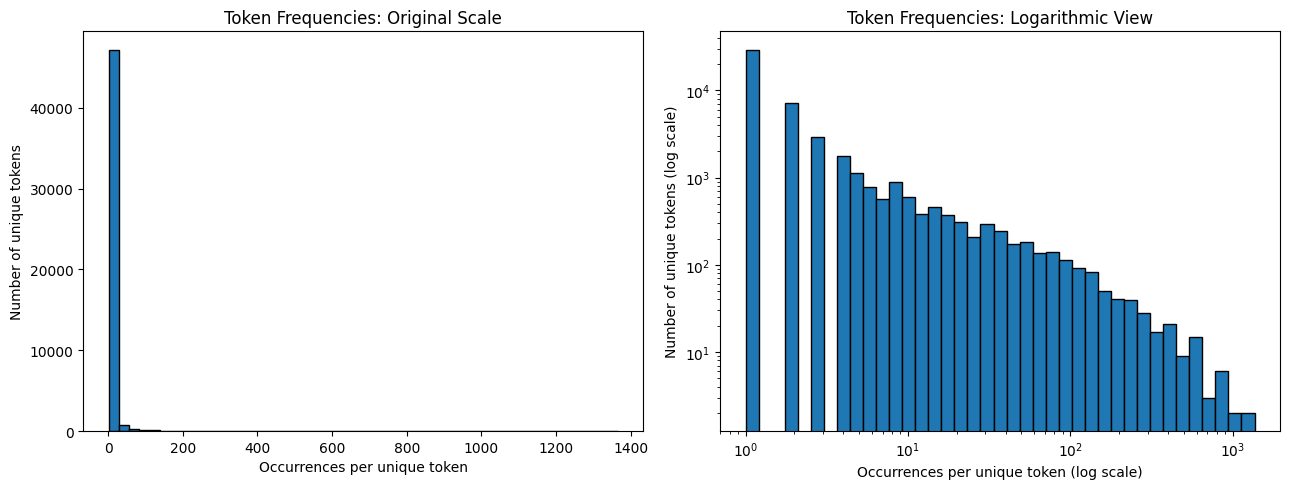

In [1]:
# Q1: Token frequencies
import pickle
import textwrap
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA


def explain(text):
    print("\n".join(textwrap.wrap(text, width=80)))


print("-- Q1 --")
data_dir = Path("data")
with (data_dir / "all_tokens.pickle").open("rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
counts = np.array(list(token_count.values()))
singleton_count = np.count_nonzero(counts == 1)
most_common_token, most_common_count = token_freq[0]
print("Top 10 tokens:", token_freq[:10])
print(f"Unique tokens: {len(token_count):,}")
print(f"Tokens occurring exactly once: {singleton_count:,}")

# Keep the original histogram and add a view that makes the tail easier to see.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(counts, bins=50, edgecolor="black")
axes[0].set_xlabel("Occurrences per unique token")
axes[0].set_ylabel("Number of unique tokens")
axes[0].set_title("Token Frequencies: Original Scale")

bins = np.geomspace(1, counts.max() + 1, 40)
axes[1].hist(counts, bins=bins, edgecolor="black")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Occurrences per unique token (log scale)")
axes[1].set_ylabel("Number of unique tokens (log scale)")
axes[1].set_title("Token Frequencies: Logarithmic View")
plt.tight_layout()
plt.show()

explain(
    f"The distribution is extremely right-skewed. Most tokens appear only a "
    f"few times, while a small number appear much more frequently. Of the "
    f"{len(token_count):,} unique tokens, {singleton_count:,} appear exactly "
    f"once. The most frequent token, {most_common_token!r}, appears "
    f"{most_common_count:,} times. The logarithmic view makes the long tail "
    f"easier to inspect. Its unequal-width bins show token counts per bin, "
    f"not a probability density."
)


In [2]:
# Q2: Data validation and regression on the original features
print("-- Q2 --")
df = pd.read_parquet(data_dir / "Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

assert X.index.equals(y.index)
assert not X.isna().any().any()
assert not y.isna().any()
assert X.isin([0, 1]).all().all()
assert set(y.unique()) == {0, 1}

feature_occurrences = X.sum()
zero_columns = int(feature_occurrences.eq(0).sum())
rare_columns = int(feature_occurrences.lt(15).sum())
duplicate_columns = int(X.T.duplicated().sum())
density = feature_occurrences.sum() / X.size
print(f"Emails: {len(X):,}; features: {X.shape[1]:,}")
print("Class counts (0 = not phishing, 1 = phishing):")
print(y.value_counts().sort_index())
print(f"All-zero columns: {zero_columns}")
print(f"Columns occurring in fewer than 15 emails: {rare_columns}")
print(f"Duplicate columns beyond their first copies: {duplicate_columns}")
print(f"Nonzero feature entries: {density:.4%}")
explain(
    f"The supplied data is binary and has no missing values, but "
    f"{rare_columns} columns occur in fewer than 15 emails, including "
    f"{zero_columns} all-zero columns. This differs from the prompt's "
    f"description. I retain the supplied features for the assignment."
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
# Reuse these matrices for fitting and scoring.
X_train_sparse = csr_matrix(X_train)
X_test_sparse = csr_matrix(X_test)
model = LinearRegression()
model.fit(X_train_sparse, y_train)
train_r2 = model.score(X_train_sparse, y_train)
test_r2 = model.score(X_test_sparse, y_test)
print(f"Training R²: {train_r2:.6f}")
print(f"Test R²: {test_r2:.6f}")

coefficients = pd.Series(model.coef_, index=X.columns)
top_words = coefficients.sort_values(key=abs, ascending=False)
print("Top 10 tokens by absolute coefficient (signed values shown):")
print(top_words.head(10).round(4))
top_five = ", ".join(repr(word) for word in top_words.head(5).index)
explain(
    f"Training R² is {train_r2:.4f}, compared with test R² of "
    f"{test_r2:.4f}. This gap suggests some overfitting. The five largest "
    f"absolute coefficients belong to {top_five}. A coefficient describes "
    f"the change in the fitted score when a token changes from absent to "
    f"present, holding the other features fixed. Positive coefficients "
    f"increase the fitted phishing score and negative coefficients decrease "
    f"it. Correlated or duplicate features can make individual coefficients "
    f"unstable or nonunique, so magnitude alone is not reliable overall "
    f"predictive importance or evidence of a causal effect. Some tokens are "
    f"HTML or formatting fragments. Linear regression scores can fall "
    f"outside [0, 1], so they are not guaranteed probabilities. R² measures "
    f"regression performance, not classification accuracy."
)


-- Q2 --
Emails: 18,634; features: 2,711
Class counts (0 = not phishing, 1 = phishing):
Email Type
0    11322
1     7312
Name: count, dtype: int64
All-zero columns: 55
Columns occurring in fewer than 15 emails: 170
Duplicate columns beyond their first copies: 67
Nonzero feature entries: 0.3146%
The supplied data is binary and has no missing values, but 170 columns occur in
fewer than 15 emails, including 55 all-zero columns. This differs from the
prompt's description. I retain the supplied features for the assignment.
Train rows: 14,907; test rows: 3,727
Training R²: 0.771349
Test R²: 0.642411
Top 10 tokens by absolute coefficient (signed values shown):
background-image:   -1.0160
localized            0.8395
thermal              0.6996
#331f30;             0.6159
#000000;             0.6158
form.                0.5937
aging                0.5867
erectile             0.5385
girlfriend           0.5276
xanaax               0.5164
dtype: float64
Training R² is 0.7713, compared with test R

-- Q3 --
Explained variance ratios: [0.011131 0.008606]
Combined explained variance: 1.97%
The phishing and non-phishing emails overlap substantially in the main cluster.
Several groups farther to the right are mostly non-phishing, while some phishing
emails concentrate higher on the second component. There is no clear separation
in this projection. However, these two components explain only 1.97% of the
feature variance, so the plot does not establish that the full feature set
cannot distinguish the classes. This full-data PCA is descriptive only; Q4 fits
a separate PCA on training data.


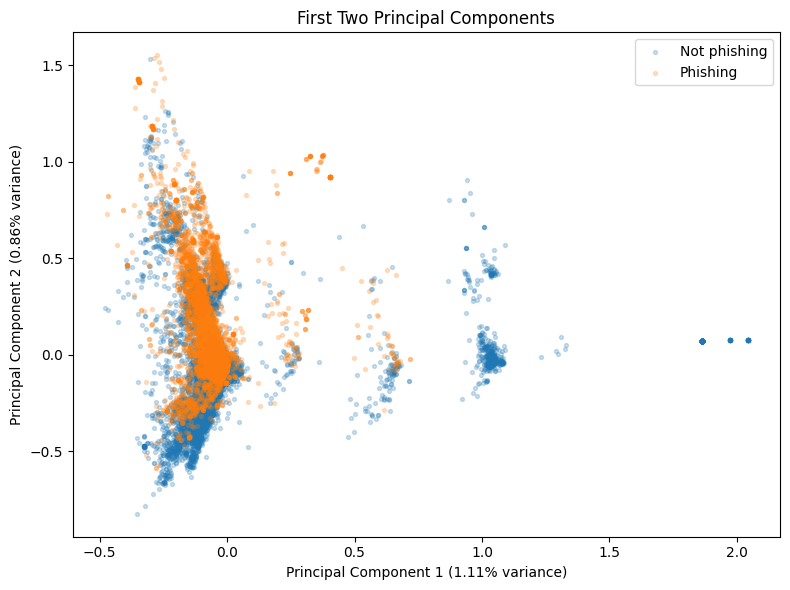

In [3]:
# Q3: Descriptive PCA plot using the full feature data
print("-- Q3 --")
pca2 = PCA(n_components=2, svd_solver="randomized", random_state=42)
X_pca2 = pca2.fit_transform(X.to_numpy(dtype=np.float32))
variance2 = pca2.explained_variance_ratio_

plt.figure(figsize=(8, 6))
for label, name in [(0, "Not phishing"), (1, "Phishing")]:
    mask = y.to_numpy() == label
    plt.scatter(
        X_pca2[mask, 0], X_pca2[mask, 1], label=name, alpha=0.23, s=8
    )
plt.xlabel(f"Principal Component 1 ({variance2[0]:.2%} variance)")
plt.ylabel(f"Principal Component 2 ({variance2[1]:.2%} variance)")
plt.title("First Two Principal Components")
plt.legend()
plt.tight_layout()
plt.show()
print("Explained variance ratios:", variance2.round(6))
print(f"Combined explained variance: {variance2.sum():.2%}")
explain(
    f"The phishing and non-phishing emails overlap substantially in the "
    f"main cluster. Several groups farther to the right are mostly "
    f"non-phishing, while some phishing emails concentrate higher on the "
    f"second component. There is no clear separation in this projection. "
    f"However, these two components explain only {variance2.sum():.2%} of "
    f"the feature variance, so the plot does not establish that the full "
    f"feature set cannot distinguish the classes. This full-data PCA is "
    f"descriptive only; Q4 fits a separate PCA on training data."
)


In [4]:
# Q4: Regression on 2,610 training-fitted principal components
print("-- Q4 --")
n_components = 2610
assert n_components <= min(X_train.shape)
# Keep float32: the precision check found no material score difference.
pca_large = PCA(n_components=n_components, svd_solver="covariance_eigh")
X_train_pca = pca_large.fit_transform(X_train.to_numpy(dtype=np.float32))
X_test_pca = pca_large.transform(X_test.to_numpy(dtype=np.float32))
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)
pca_train_r2 = pca_model.score(X_train_pca, y_train)
pca_test_r2 = pca_model.score(X_test_pca, y_test)
retained_variance = pca_large.explained_variance_ratio_.sum()

results = pd.DataFrame(
    {
        "Training R²": [train_r2, pca_train_r2],
        "Test R²": [test_r2, pca_test_r2],
    },
    index=["Original features", f"{n_components:,} principal components"],
)
print(results.to_string(float_format=lambda value: f"{value:.6f}"))
train_change = pca_train_r2 - train_r2
test_change = pca_test_r2 - test_r2
print(f"Change in training R² (PCA - original): {train_change:+.6f}")
print(f"Change in test R² (PCA - original): {test_change:+.6f}")
print(f"Training-feature variance retained: {retained_variance:.4%}")
explain(
    f"With {n_components:,} components, training R² is "
    f"{pca_train_r2:.4f} and test R² is {pca_test_r2:.4f}. Relative to "
    f"the original regression, the changes are {train_change:+.4f} and "
    f"{test_change:+.4f}, respectively. The slightly lower training score "
    f"and slightly higher test score are consistent with a small reduction "
    f"in overfitting on this split, but do not establish a reliable "
    f"improvement across other splits. PCA removes lower-variance "
    f"directions, which are not necessarily less useful for prediction. "
    f"The retained components capture {retained_variance:.4%} of the "
    f"training-feature variance, helping explain the similar performance; "
    f"retained variance alone does not guarantee predictive performance."
)


-- Q4 --
                            Training R²  Test R²
Original features              0.771349 0.642411
2,610 principal components     0.770741 0.644963
Change in training R² (PCA - original): -0.000608
Change in test R² (PCA - original): +0.002552
Training-feature variance retained: 99.9857%
With 2,610 components, training R² is 0.7707 and test R² is 0.6450. Relative to
the original regression, the changes are -0.0006 and +0.0026, respectively. The
slightly lower training score and slightly higher test score are consistent with
a small reduction in overfitting on this split, but do not establish a reliable
improvement across other splits. PCA removes lower-variance directions, which
are not necessarily less useful for prediction. The retained components capture
99.9857% of the training-feature variance, helping explain the similar
performance; retained variance alone does not guarantee predictive performance.


In [5]:
# Q5: Advantages and limitations of principal component regression
print("-- Q5 --")
feature_reduction = 1 - n_components / X.shape[1]
explain(
    f"PCA combines the original token features into components whose "
    f"scores are uncorrelated on the data used to fit PCA. Retaining fewer "
    f"components can reduce redundancy, improve numerical conditioning, "
    f"and reduce overfitting, but improved prediction is not guaranteed. "
    f"PCA chooses directions using feature variance rather than the target, "
    f"so a discarded low-variance direction may still help predict phishing. "
    f"Components are also harder to interpret than individual tokens. "
    f"Here, keeping {n_components:,} of {X.shape[1]:,} components reduces "
    f"the predictor count by only {feature_reduction:.2%}. Because PCA "
    f"adds computation and produces dense scores, this workflow is not "
    f"necessarily faster than the original sparse regression. The observed "
    f"test-R² change is {test_change:+.4f}; classification accuracy was "
    f"not measured."
)


-- Q5 --
PCA combines the original token features into components whose scores are
uncorrelated on the data used to fit PCA. Retaining fewer components can reduce
redundancy, improve numerical conditioning, and reduce overfitting, but improved
prediction is not guaranteed. PCA chooses directions using feature variance
rather than the target, so a discarded low-variance direction may still help
predict phishing. Components are also harder to interpret than individual
tokens. Here, keeping 2,610 of 2,711 components reduces the predictor count by
only 3.73%. Because PCA adds computation and produces dense scores, this
workflow is not necessarily faster than the original sparse regression. The
observed test-R² change is +0.0026; classification accuracy was not measured.


### *Reflection on AI assistance
In your own words without generative AI.

Using the AI genuinely did allow for very much revised code, with output that I felt was a lot more clear and descriptive. I felt that the histogram was much cleaner. There were proper data validation checks. The explanation of PCA's limitations was improved and there were numerical summaries that were automatically generated. I did decide to keep float32 rather than listening to the AI just because the comparison showed a rather negligible difference in the test R^2 so it didn't really seem worth the additional memory to switch that precision. I learned that PCA preserves the directions with high feature variance, which doesn't necessarily serve as the most useful ones for predicting phishing. The first two components only explain around 1.97% of the variance so that overlap doesn't say that the full dataset is unable to separate classes. Overall I continue to find a lot of usefulness in using AI here since it genuinely helps with having more readable code with much better outputs that report far more effectively. 